# CareerMind — Agent 3: Job Clustering (Final Optimisation)

**Methods:** TF-IDF, PCA (only because it is useful for this experiment), K-Means, Hierarchical/Agglomerative Clustering, DBSCAN and Silhouette Score.

This notebook investigates a silhouette-optimised representation based on **job title + skills**. It compares a small number of feature/PCA configurations without using `job_category` to train, tune or select a model. `job_category` is reserved for post-clustering interpretation only.



## 1. Setup and Load Dataset

In [1]:
import os, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

BASE = "/content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind"
DATA_DIR = os.path.join(BASE, "Data")
CLEAN_DIR = os.path.join(DATA_DIR, "Cleaned")
MODEL_DIR = os.path.join(BASE, "Models")
GROUPING_DIR = os.path.join(MODEL_DIR, "Grouping", "final_silhouette_optimised")
RESULTS_DIR = os.path.join(BASE, "Results", "final_silhouette_optimised")
PROCESSED_DIR = os.path.join(DATA_DIR, "Processed")
for folder in [GROUPING_DIR, RESULTS_DIR, PROCESSED_DIR]:
    os.makedirs(folder, exist_ok=True)

DATA_PATH = os.path.join(CLEAN_DIR, "careermind_master_dataset_v2.csv")
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Mounted at /content/drive
Dataset shape: (6000, 15)


,job_id,job_title,job_description,skills,experience_min_years,experience_max_years,experience_midpoint_years,experience_level,location,job_category,minimum_annual_salary_inr,maximum_annual_salary_inr,average_annual_salary_inr,currency,salary_period
0,CM000760,Engineer,Collaborates with business and technical teams...,"NumPy, Project Coordination",7,11,9.0,Senior,Hyderabad,Data Science & AI,2420000,2920000,2670000,INR,Annual
1,CM002306,Operations Associate,"Reviews workflows, prepares status updates, su...","Linux, Firewalls, Python, Data Analysis, Tally",4,7,5.5,Mid Level,Gurugram,Cybersecurity,900000,1180000,1040000,INR,Annual
2,CM002285,Security Analyst,"Collects and reviews information, identifies i...","Incident Response, SIEM, Python, Communication...",4,7,5.5,Mid Level,Jaipur,Cybersecurity,970000,1250000,1110000,INR,Annual
3,CM002352,Developer,"Helps plan and execute team activities, checks...","SIEM, Network Security, Firewalls, Python, Pro...",1,2,1.5,Junior,Ahmedabad,Cybersecurity,590000,730000,660000,INR,Annual
4,CM003961,Technical Analyst,plans digital campaigns and evaluates audience...,"Social Media, Excel, Problem Solving",1,2,1.5,Junior,Bengaluru,Marketing,450000,570000,510000,INR,Annual


## 2. Validate Dataset

In [2]:
required_columns = [
    "job_id", "job_title", "skills", "job_description", "location",
    "experience_level", "experience_midpoint_years",
    "average_annual_salary_inr", "job_category"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Missing values in required columns:")
print(df[required_columns].isna().sum())
print("Duplicate job IDs:", df["job_id"].duplicated().sum())
if df["job_id"].duplicated().any():
    raise ValueError("job_id must be unique for this workflow.")

# Text fields can be empty; convert them to strings safely.
for col in ["job_title", "skills", "job_description"]:
    df[col] = df[col].fillna("").astype(str)

print("Validation complete. Rows:", len(df))

Missing values in required columns:
job_id                       0
job_title                    0
skills                       0
job_description              0
location                     0
experience_level             0
experience_midpoint_years    0
average_annual_salary_inr    0
job_category                 0
dtype: int64
Duplicate job IDs: 0
Validation complete. Rows: 6000


## 3. Exploratory Data Analysis

,job_title,skills,location,experience_level
0,Engineer,"NumPy, Project Coordination",Hyderabad,Senior
1,Operations Associate,"Linux, Firewalls, Python, Data Analysis, Tally",Gurugram,Mid Level
2,Security Analyst,"Incident Response, SIEM, Python, Communication...",Jaipur,Mid Level
3,Developer,"SIEM, Network Security, Firewalls, Python, Pro...",Ahmedabad,Junior
4,Technical Analyst,"Social Media, Excel, Problem Solving",Bengaluru,Junior
5,Technical Analyst,"Statistics, Excel, SQL, Problem Solving, Agile",Noida,Senior
6,Associate,"Excel, Documentation, Payroll",Pune,Senior
7,Engineer,"API Testing, Java, Manual Testing, Python",Jaipur,Lead
8,Associate,"Adobe XD, Usability Testing, Excel, Documentat...",Remote India,Junior
9,Engineer,"TensorFlow, Statistics, Documentation, Data An...",Mumbai,Lead


Unique job titles: 58
Unique skill strings: 5932
Unique job categories (interpretation only): 12


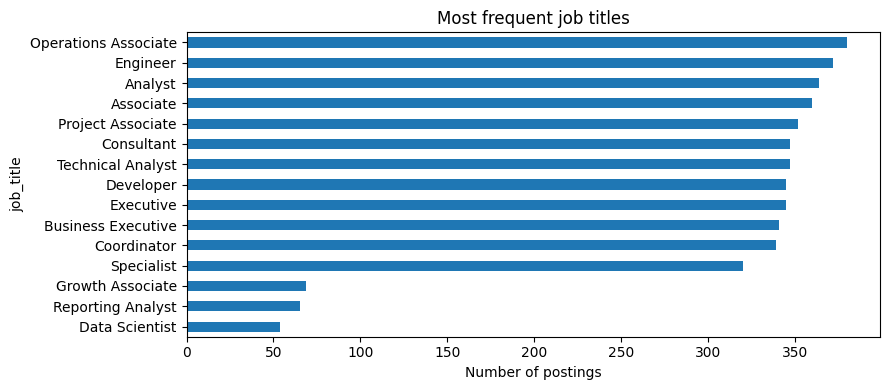

In [3]:
display(df[["job_title", "skills", "location", "experience_level"]].head(10))
print("Unique job titles:", df["job_title"].nunique())
print("Unique skill strings:", df["skills"].nunique())
print("Unique job categories (interpretation only):", df["job_category"].nunique())

plt.figure(figsize=(9, 4))
df["job_title"].value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Most frequent job titles")
plt.xlabel("Number of postings")
plt.tight_layout()
plt.show()

## 4. Feature Engineering

Claude's experiment found that **job title + skills** produced the strongest silhouette result. Location is excluded because it can create location-based separation rather than job-content similarity. Salary and experience are also excluded from the primary silhouette-optimised representation.

`job_category` and `job_id` are never model inputs.

In [4]:
work = df.copy()
work["cluster_text"] = (
    work["job_title"].str.strip() + " " + work["skills"].str.strip()
).str.strip()

if (work["cluster_text"].str.len() == 0).any():
    raise ValueError("Some records have no title or skills text. Inspect these rows before clustering.")

print("Text feature example:")
print(work["cluster_text"].iloc[0])

Text feature example:
Engineer NumPy, Project Coordination


## 5. TF-IDF Text Representation

In [5]:
# TF-IDF is applied only to job title + skills.
# Keep the configuration simple and reproducible.
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000,
    dtype=np.float32
)
X_tfidf = tfidf.fit_transform(work["cluster_text"])
print("TF-IDF matrix:", X_tfidf.shape)
print("Non-zero entries:", X_tfidf.nnz)

TF-IDF matrix: (6000, 3033)
Non-zero entries: 89050


## 6. PCA Dimensionality Reduction

PCA is used here as a syllabus technique and because Claude's experiment found that a very low-dimensional representation produced a higher silhouette score on this dataset. PCA requires a dense input, so we convert the TF-IDF matrix to `float32` before fitting. This step can require additional RAM in Colab.

We compare 2 and 3 components. We do not assume that fewer components mean better semantic clusters.

In [6]:
X_dense = X_tfidf.toarray().astype(np.float32, copy=False)
print("Dense matrix memory (approx. MB):", round(X_dense.nbytes / (1024**2), 1))

pca_models = {}
X_pca_by_dim = {}
for n_components in [2, 3]:
    pca_model = PCA(n_components=n_components, svd_solver="randomized", random_state=RANDOM_STATE)
    X_pca = pca_model.fit_transform(X_dense)
    pca_models[n_components] = pca_model
    X_pca_by_dim[n_components] = X_pca
    print(
        f"PCA {n_components} components | shape={X_pca.shape} | "
        f"variance captured={pca_model.explained_variance_ratio_.sum():.4f}"
    )

Dense matrix memory (approx. MB): 69.4
PCA 2 components | shape=(6000, 2) | variance captured=0.0233
PCA 3 components | shape=(6000, 3) | variance captured=0.0332


## 7. K-Means Experiments and Configuration Selection

In [7]:
# Evaluate K from 6 to 10, as recommended by the comparative experiment.
# Selection uses only Silhouette Score, never job_category.
kmeans_rows = []
kmeans_candidates = {}

for n_components, X_pca in X_pca_by_dim.items():
    for k in range(6, 11):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
        labels = model.fit_predict(X_pca)
        score = silhouette_score(X_pca, labels)
        key = (n_components, k)
        kmeans_candidates[key] = model
        kmeans_rows.append({
            "Features": "job_title + skills",
            "PCA components": n_components,
            "K": k,
            "Clusters": len(np.unique(labels)),
            "Silhouette": score,
            "Coverage": 1.0
        })

kmeans_results = pd.DataFrame(kmeans_rows).sort_values("Silhouette", ascending=False)
display(kmeans_results.round(4))

best_row = kmeans_results.iloc[0]
best_components = int(best_row["PCA components"])
best_k = int(best_row["K"])
X_selected = X_pca_by_dim[best_components]
print("Selected PCA components:", best_components)
print("Selected K:", best_k)
print("Selected K-Means silhouette:", round(float(best_row["Silhouette"]), 4))

,Features,PCA components,K,Clusters,Silhouette,Coverage
1,job_title + skills,2,7,7,0.7111,1.0
0,job_title + skills,2,6,6,0.6821,1.0
2,job_title + skills,2,8,8,0.6694,1.0
6,job_title + skills,3,7,7,0.6614,1.0
5,job_title + skills,3,6,6,0.6376,1.0
3,job_title + skills,2,9,9,0.6294,1.0
7,job_title + skills,3,8,8,0.6206,1.0
4,job_title + skills,2,10,10,0.5919,1.0
8,job_title + skills,3,9,9,0.5692,1.0
9,job_title + skills,3,10,10,0.4412,1.0


Selected PCA components: 2
Selected K: 7
Selected K-Means silhouette: 0.7111


## 8. K-Means Silhouette Visualisation

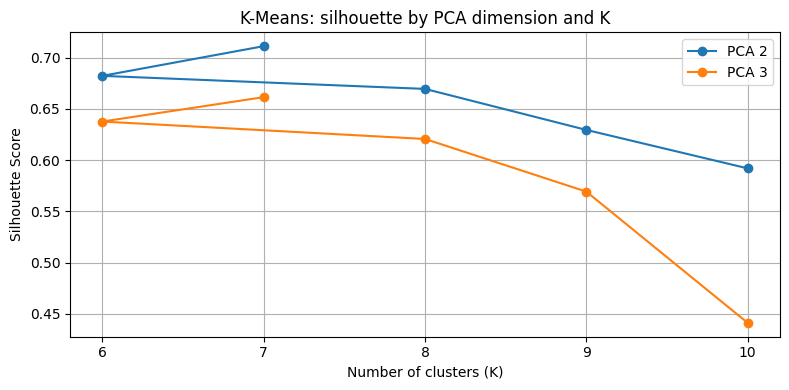

In [8]:
plt.figure(figsize=(8, 4))
for n_components in sorted(kmeans_results["PCA components"].unique()):
    subset = kmeans_results[kmeans_results["PCA components"] == n_components]
    plt.plot(subset["K"], subset["Silhouette"], marker="o", label=f"PCA {n_components}")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: silhouette by PCA dimension and K")
plt.xticks(range(6, 11))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Hierarchical / Agglomerative Clustering

Agglomerative clustering is computationally more expensive than K-Means. For a fair algorithm comparison, all three algorithms below use the same fixed, reproducible evaluation sample from the selected PCA representation.

In [9]:
EVAL_N = min(2500, len(X_selected))
rng = np.random.default_rng(RANDOM_STATE)
eval_indices = np.sort(rng.choice(len(X_selected), size=EVAL_N, replace=False))
X_eval = X_selected[eval_indices]
print("Shared algorithm comparison sample:", X_eval.shape)

hierarchical_rows = []
hierarchical_candidates = {}
for k in range(6, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_eval)
    score = silhouette_score(X_eval, labels)
    hierarchical_candidates[k] = (model, labels)
    hierarchical_rows.append({
        "Algorithm": "Hierarchical",
        "Parameters": f"K={k}",
        "Clusters": len(np.unique(labels)),
        "Silhouette": score,
        "Noise points": 0,
        "Coverage": 1.0
    })
hierarchical_results = pd.DataFrame(hierarchical_rows)
display(hierarchical_results.round(4))

Shared algorithm comparison sample: (2500, 2)


,Algorithm,Parameters,Clusters,Silhouette,Noise points,Coverage
0,Hierarchical,K=6,6,0.6616,0,1.0
1,Hierarchical,K=7,7,0.6827,0,1.0
2,Hierarchical,K=8,8,0.6478,0,1.0
3,Hierarchical,K=9,9,0.6176,0,1.0
4,Hierarchical,K=10,10,0.6162,0,1.0


## 10. DBSCAN Experiments

In [10]:
dbscan_rows = []
dbscan_candidates = {}

for eps in [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    for min_samples in [5, 10]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_eval)
        non_noise_mask = labels != -1
        cluster_labels = labels[non_noise_mask]
        n_clusters = len(set(cluster_labels))
        noise_count = int((~non_noise_mask).sum())
        coverage = float(non_noise_mask.mean())
        score = np.nan
        # Silhouette excludes noise only; coverage is always reported beside it.
        if n_clusters >= 2 and non_noise_mask.sum() > n_clusters:
            score = silhouette_score(X_eval[non_noise_mask], cluster_labels)
        row = {
            "Algorithm": "DBSCAN",
            "Parameters": f"eps={eps}, min_samples={min_samples}",
            "Clusters": n_clusters,
            "Silhouette": score,
            "Noise points": noise_count,
            "Coverage": coverage
        }
        dbscan_rows.append(row)
        dbscan_candidates[(eps, min_samples)] = (model, labels)

dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round(4))

,Algorithm,Parameters,Clusters,Silhouette,Noise points,Coverage
0,DBSCAN,"eps=0.05, min_samples=5",1,NaN,7,0.9972
1,DBSCAN,"eps=0.05, min_samples=10",2,0.4745,12,0.9952
2,DBSCAN,"eps=0.1, min_samples=5",1,NaN,0,1.0000
3,DBSCAN,"eps=0.1, min_samples=10",1,NaN,0,1.0000
4,DBSCAN,"eps=0.15, min_samples=5",1,NaN,0,1.0000
5,DBSCAN,"eps=0.15, min_samples=10",1,NaN,0,1.0000
6,DBSCAN,"eps=0.2, min_samples=5",1,NaN,0,1.0000
7,DBSCAN,"eps=0.2, min_samples=10",1,NaN,0,1.0000
8,DBSCAN,"eps=0.3, min_samples=5",1,NaN,0,1.0000
9,DBSCAN,"eps=0.3, min_samples=10",1,NaN,0,1.0000


## 11. Compare All Three Algorithms

K-Means and Hierarchical scores use all records in the shared evaluation sample. DBSCAN's silhouette is calculated only among non-noise records, so its coverage must be considered alongside the score. A DBSCAN score with very low coverage is not treated as a practical winner.

In [11]:
# K-Means on the exact same evaluation sample
comparison_kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
km_eval_labels = comparison_kmeans.fit_predict(X_eval)
comparison_rows = [{
    "Algorithm": "K-Means",
    "Parameters": f"K={best_k}",
    "Clusters": len(np.unique(km_eval_labels)),
    "Silhouette": silhouette_score(X_eval, km_eval_labels),
    "Noise points": 0,
    "Coverage": 1.0
}]

# Best Hierarchical configuration
best_hier = hierarchical_results.sort_values("Silhouette", ascending=False).iloc[0]
best_hier_k = int(str(best_hier["Parameters"]).split("=")[1])
hier_model, hier_eval_labels = hierarchical_candidates[best_hier_k]
comparison_rows.append({
    "Algorithm": "Hierarchical",
    "Parameters": f"K={best_hier_k}",
    "Clusters": len(np.unique(hier_eval_labels)),
    "Silhouette": silhouette_score(X_eval, hier_eval_labels),
    "Noise points": 0,
    "Coverage": 1.0
})

# Best DBSCAN by silhouette subject to a minimum coverage of 50%.
valid_dbscan = dbscan_results[
    dbscan_results["Silhouette"].notna() & (dbscan_results["Coverage"] >= 0.50)
]
if len(valid_dbscan):
    best_db = valid_dbscan.sort_values("Silhouette", ascending=False).iloc[0]
    best_eps = float(str(best_db["Parameters"]).split(",")[0].split("=")[1])
    best_min_samples = int(str(best_db["Parameters"]).split("min_samples=")[1])
    comparison_rows.append(best_db.to_dict())
    print("Best DBSCAN meeting 50% coverage:", best_db["Parameters"])
else:
    print("No DBSCAN configuration achieved at least 50% coverage with 2+ clusters.")

algorithm_comparison = pd.DataFrame(comparison_rows)
display(algorithm_comparison.round(4))

Best DBSCAN meeting 50% coverage: eps=0.05, min_samples=10


,Algorithm,Parameters,Clusters,Silhouette,Noise points,Coverage
0,K-Means,K=7,7,0.7054,0,1.0000
1,Hierarchical,K=7,7,0.6827,0,1.0000
2,DBSCAN,"eps=0.05, min_samples=10",2,0.4745,12,0.9952


## 12. Select and Fit Final Deployable K-Means Model

In [12]:
# Refit the selected configuration on all available job postings.
final_kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
final_labels = final_kmeans.fit_predict(X_selected)
work["cluster_id"] = final_labels

final_silhouette = float(silhouette_score(X_selected, final_labels))
print("Final deployable model: K-Means")
print("PCA components:", best_components)
print("K:", best_k)
print("Rows clustered:", len(final_labels))
print("Coverage: 100%")
print("Full-data Silhouette Score:", round(final_silhouette, 4))

Final deployable model: K-Means
PCA components: 2
K: 7
Rows clustered: 6000
Coverage: 100%
Full-data Silhouette Score: 0.7111


## 13. Visualise Final Clusters

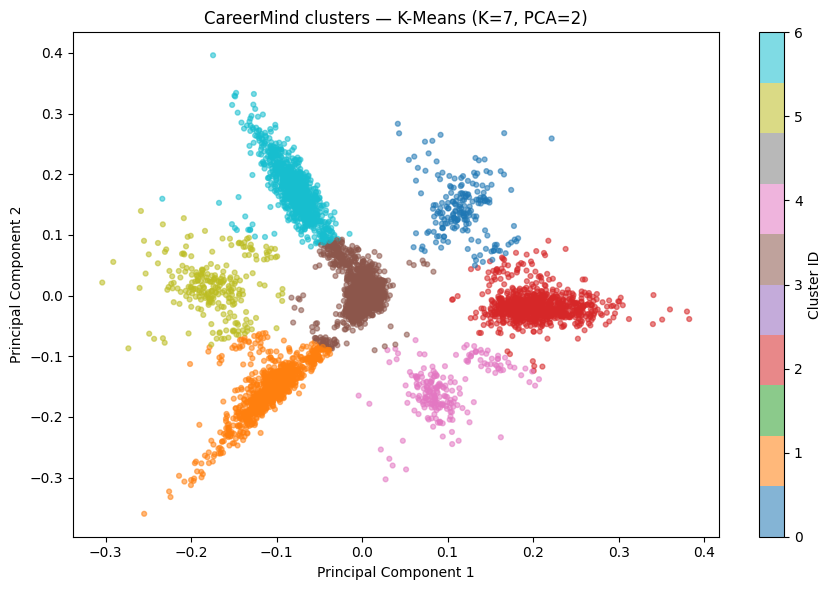

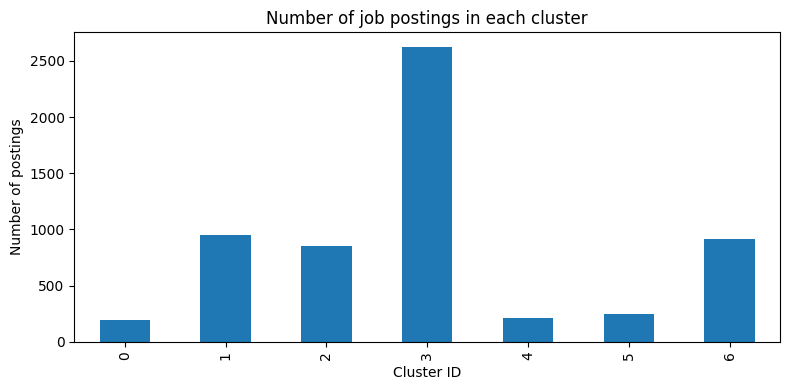

In [13]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_selected[:, 0], X_selected[:, 1],
    c=final_labels, cmap="tab10", s=12, alpha=0.55
)
plt.title(f"CareerMind clusters — K-Means (K={best_k}, PCA={best_components})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
work["cluster_id"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of job postings in each cluster")
plt.xlabel("Cluster ID")
plt.ylabel("Number of postings")
plt.tight_layout()
plt.show()

## 14. Cluster Profiles and Interpretation

Cluster IDs are geometric groups, not job categories. The category distribution below is inspected only after the clustering model has been selected and trained. Mixed category distributions must be described honestly.

In [14]:
cluster_profile = work.groupby("cluster_id").agg(
    job_count=("job_id", "count"),
    top_job_title=("job_title", lambda x: x.value_counts().index[0]),
    top_location=("location", lambda x: x.value_counts().index[0]),
    average_experience=("experience_midpoint_years", "mean"),
    average_salary_inr=("average_annual_salary_inr", "mean"),
    most_common_category=("job_category", lambda x: x.value_counts().index[0])
).reset_index()

# Category proportions are post-hoc descriptive information only.
category_mix = pd.crosstab(work["cluster_id"], work["job_category"], normalize="index")

def top_skills_for_cluster(cluster_id, top_n=10):
    subset = work.loc[work["cluster_id"] == cluster_id, "skills"].fillna("").astype(str)
    tokens = []
    for value in subset:
        tokens.extend([token.strip() for token in value.split(",") if token.strip()])
    return pd.Series(tokens).value_counts().head(top_n).index.tolist()

cluster_profile["common_skills"] = cluster_profile["cluster_id"].apply(
    lambda cid: ", ".join(top_skills_for_cluster(cid))
)
display(cluster_profile.round(2))
display(category_mix.round(3))

,cluster_id,job_count,top_job_title,top_location,average_experience,average_salary_inr,most_common_category,common_skills
0,0,195,Operations Associate,Hyderabad,5.07,860871.79,Data Analytics,"Problem Solving, Data Analysis, SQL, Excel, Py..."
1,1,953,Project Associate,Gurugram,5.55,882214.06,Human Resources,"Project Coordination, Python, Excel, SQL, Git,..."
2,2,853,Engineer,Noida,5.74,901641.27,Data Science & AI,"Problem Solving, Excel, Python, SQL, Agile, Co..."
3,3,2623,Developer,Chennai,5.39,879359.51,Finance & Accounting,"Excel, Python, Communication, SQL, Git, Docume..."
4,4,212,Project Associate,Noida,5.31,910943.40,Cloud & DevOps,"Problem Solving, Project Coordination, Python,..."
5,5,249,Project Associate,Noida,5.62,908755.02,Data Analytics,"Project Coordination, Data Analysis, Python, E..."
6,6,915,Analyst,Bengaluru,5.71,898404.37,Data Analytics,"Data Analysis, Excel, Python, SQL, Communicati..."


job_category,Cloud & DevOps,Cybersecurity,Data Analytics,Data Science & AI,Finance & Accounting,Human Resources,Marketing,Operations & Supply Chain,QA & Testing,Sales,Software Development,UI/UX & Design
cluster_id,,,,,,,,,,,,
0,0.072,0.067,0.164,0.077,0.067,0.062,0.062,0.108,0.077,0.067,0.123,0.056
1,0.090,0.089,0.064,0.082,0.075,0.098,0.082,0.092,0.085,0.090,0.071,0.082
2,0.087,0.072,0.061,0.102,0.093,0.095,0.086,0.075,0.082,0.090,0.069,0.089
3,0.081,0.088,0.059,0.086,0.096,0.084,0.088,0.082,0.081,0.085,0.079,0.091
4,0.127,0.108,0.042,0.061,0.061,0.047,0.104,0.071,0.127,0.094,0.094,0.061
5,0.096,0.068,0.169,0.056,0.064,0.068,0.036,0.100,0.092,0.072,0.112,0.064
6,0.069,0.077,0.163,0.074,0.062,0.073,0.081,0.079,0.079,0.069,0.103,0.072


## 15. Save Model Artifacts and Results

In [15]:
model_bundle = {
    "tfidf_vectorizer": tfidf,
    "pca": pca_models[best_components],
    "kmeans": final_kmeans,
    "text_columns": ["job_title", "skills"],
    "selected_pca_components": best_components,
    "selected_k": best_k,
    "random_state": RANDOM_STATE,
    "feature_description": "TF-IDF of job_title + skills, transformed using PCA"
}

bundle_path = os.path.join(GROUPING_DIR, "careermind_final_clustering_bundle.joblib")
joblib.dump(model_bundle, bundle_path)

cluster_profile.to_csv(os.path.join(RESULTS_DIR, "cluster_profiles.csv"), index=False)
category_mix.to_csv(os.path.join(RESULTS_DIR, "cluster_category_mix_posthoc.csv"))
kmeans_results.to_csv(os.path.join(RESULTS_DIR, "kmeans_experiments.csv"), index=False)
hierarchical_results.to_csv(os.path.join(RESULTS_DIR, "hierarchical_experiments.csv"), index=False)
dbscan_results.to_csv(os.path.join(RESULTS_DIR, "dbscan_experiments.csv"), index=False)
algorithm_comparison.to_csv(os.path.join(RESULTS_DIR, "algorithm_comparison.csv"), index=False)
work.to_csv(os.path.join(PROCESSED_DIR, "clustering_with_final_labels.csv"), index=False)

summary = {
    "agent": "Job Clustering",
    "dataset_type": "synthetic academic dataset",
    "deployable_model": "K-Means",
    "input_features": ["job_title", "skills"],
    "pca_components": best_components,
    "selected_k": best_k,
    "silhouette_full_dataset": final_silhouette,
    "coverage": 1.0,
    "dataset_rows": int(len(work)),
    "label_usage": "job_category excluded from training and selection; used only for post-hoc interpretation"
}
with open(os.path.join(RESULTS_DIR, "clustering_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Saved model bundle:", bundle_path)
print("Saved results:", RESULTS_DIR)

Saved model bundle: /content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind/Models/Grouping/final_silhouette_optimised/careermind_final_clustering_bundle.joblib
Saved results: /content/drive/.shortcut-targets-by-id/1IxCYpLimAWYB151hnChx-TeglPEVDRrE/CareerMind/Results/final_silhouette_optimised


## 16. Test New Job Assignment

In [16]:
# Load the saved bundle to verify that deployment artifacts work.
loaded_bundle = joblib.load(bundle_path)

new_job_title = "Data Scientist"
new_job_skills = "Python, SQL, Machine Learning, Statistics, Data Analysis"
new_text = [f"{new_job_title} {new_job_skills}"]
new_tfidf = loaded_bundle["tfidf_vectorizer"].transform(new_text)
new_dense = new_tfidf.toarray().astype(np.float32, copy=False)
new_pca = loaded_bundle["pca"].transform(new_dense)
predicted_cluster = int(loaded_bundle["kmeans"].predict(new_pca)[0])

print("New job:", new_job_title)
print("Assigned cluster:", predicted_cluster)
print("Cluster profile:")
display(cluster_profile[cluster_profile["cluster_id"] == predicted_cluster])

New job: Data Scientist
Assigned cluster: 6
Cluster profile:


,cluster_id,job_count,top_job_title,top_location,average_experience,average_salary_inr,most_common_category,common_skills
6,6,915,Analyst,Bengaluru,5.714754,898404.371585,Data Analytics,"Data Analysis, Excel, Python, SQL, Communicati..."


## 17. Reusable Prediction Function

In [17]:
def assign_job_to_cluster(job_title, skills, bundle_path=bundle_path):
    """Assign a new job posting to one of the learned K-Means clusters."""
    bundle = joblib.load(bundle_path)
    text = [f"{job_title or ''} {skills or ''}".strip()]
    tfidf_matrix = bundle["tfidf_vectorizer"].transform(text)
    dense_matrix = tfidf_matrix.toarray().astype(np.float32, copy=False)
    reduced = bundle["pca"].transform(dense_matrix)
    cluster_id = int(bundle["kmeans"].predict(reduced)[0])
    return cluster_id

# Example
print("Predicted cluster:", assign_job_to_cluster(
    "Frontend Developer",
    "HTML, CSS, JavaScript, React, TypeScript"
))

Predicted cluster: 3


## 18. Final Conclusion and Limitations

- The primary deployable model is K-Means because it supports assigning new job postings to existing clusters.
- The selected features are job title and skills, represented using TF-IDF and PCA.
- K is selected using Silhouette Score only; `job_category` is not used during training or model selection.
- Hierarchical Clustering and DBSCAN are compared on the same evaluation sample. DBSCAN silhouette is reported together with coverage because noise points are excluded from its silhouette calculation.
- A high silhouette score in a 2D PCA space does not guarantee semantically meaningful job families. Cluster profiles and category mixtures must be discussed honestly.
- The dataset is synthetic, so the results are an academic demonstration and should not be generalized to the real Indian job market.

**Do not claim a target score unless the executed notebook output actually achieves it.**

In [18]:

df["cluster"] = final_labels

for cluster_id in sorted(df["cluster"].unique()):
    cluster_data = df[df["cluster"] == cluster_id]

    print(f"\nCLUSTER {cluster_id}")
    print("Number of jobs:", len(cluster_data))
    print("\nTop job titles:")
    print(cluster_data["job_title"].value_counts().head(10))
    print("\nTop skills:")
    print(cluster_data["skills"].value_counts().head(10))



CLUSTER 0
Number of jobs: 195

Top job titles:
job_title
Operations Associate    15
Business Executive      14
Analyst                 14
Coordinator             14
Specialist              14
Technical Analyst       13
Executive               13
Engineer                12
Developer               11
Consultant              11
Name: count, dtype: int64

Top skills:
skills
Statistics, Problem Solving, API Testing, Data Analysis                                                 1
Salesforce, Lead Generation, Problem Solving, Data Structures, Accounting                               1
Network Security, Incident Response, Vulnerability Assessment, Data Analysis, Agile, Problem Solving    1
TypeScript, Problem Solving, Data Analysis, Onboarding                                                  1
Linux, Vulnerability Assessment, Excel, Git, Data Analysis, Problem Solving, React                      1
Excel, Supply Chain, Communication, Data Analysis, Problem Solving, CI/CD                       